# Chew-Mandelstam Formalism

$$C_i(s; M_i, m_i) = \left[ \frac{M_i^2 - m_i^2}{\pi s} - \frac{M_i^2 + m_i^2}{\pi (M_i^2 - m_i^2)} \right] \ln\left(\frac{m_i}{M_i}\right) + \frac{1}{\pi} + \frac{\rho_i(s)}{\pi} \ln\left[ \frac{\sqrt{s_{th,i} - s} - \sqrt{(M_i - m_i)^2 - s}}{\sqrt{s_{th,i} - s} + \sqrt{(M_i - m_i)^2 - s}} \right]$$
where $\rho_i(s) = \lambda^{1/2}(s, M_i^2, m_i^2) / s$.
$$T(s) = \left[ K^{-1} - C(s) \right]^{-1}, \quad \text{where } K = \begin{pmatrix} K_{11} & K_{12} \\ K_{12} & K_{22} \end{pmatrix}$$
$$\frac{\mathrm{d}N}{\mathrm{d}M} = N_a \cdot p_1(s) \cdot |T_{11}(s) + \alpha_2 T_{12}(s)|^2$$
where $p_1(s) = \lambda^{1/2}(s, M_1^2, m_1^2)/({2\sqrt{s}})$ 

# For the Stable Case

           MINUIT Fit Parameter Table (Frazer-Hendry Unstable Case, Raw Yield)            
Parameter    | Fitted Value |  Uncertainty
------------------------------------------------------------------------------------------
K11          |      0.07684 |      0.02336
K12          |      0.55362 |      0.01061
K22          |      1.39606 |      0.00986
alpha2       |     -0.35311 |      0.00686
Na           |   2036.07529 |    763.16668
------------------------------------------------------------------------------------------
Total Chi^2       : 50.705
Degrees of Freedom: 52
Chi^2 / dof       : 0.975
S-Matrix Pole: W_pole = 3.874906 + i(-0.000346) GeV
Pole Mass   M_R   : 3874.906 MeV
Pole Width  Gamma : 0.692 MeV
------------------------------------------------------------------------
Ch 1 Angle theta1 = -1.75° | k1 = 0.749619 + i(-0.022926) | Re*Im<0: True
Ch 2 Angle theta2 = 120.36° | k2 = -0.100330 + i(0.171277) | Re*Im<0: True
Identified Riemann Sheet    : Sheet II [bt]


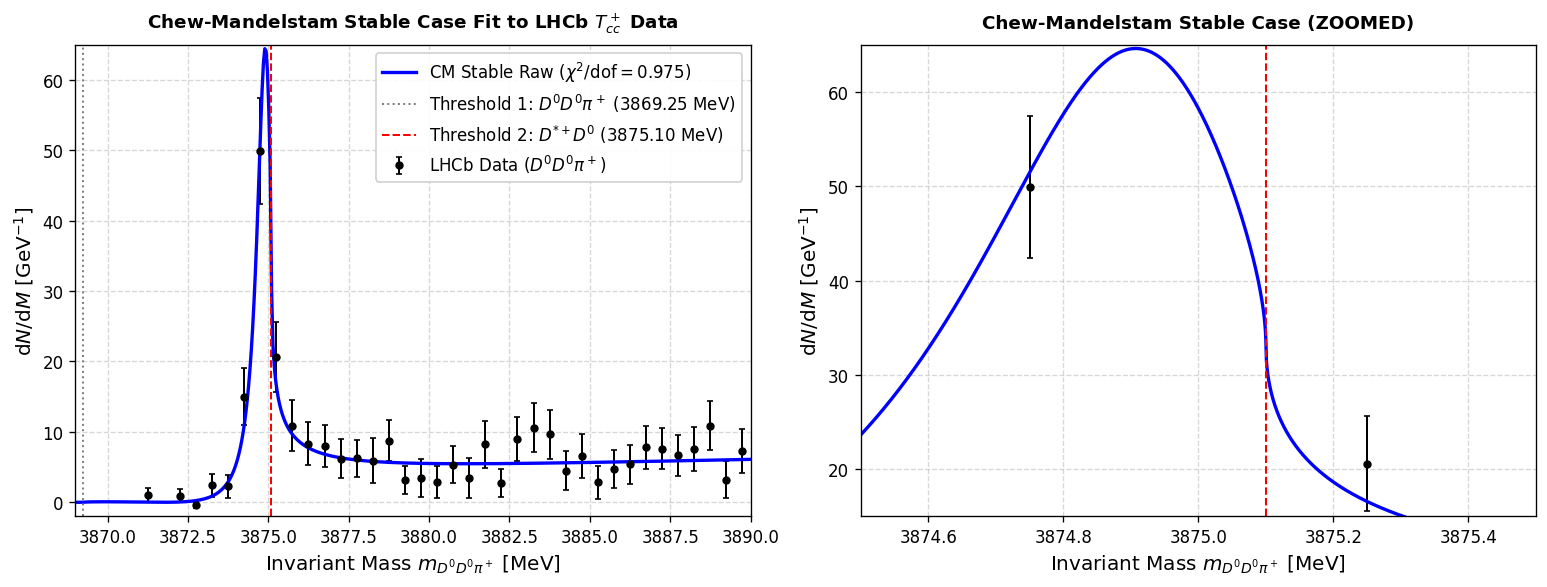

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from iminuit import Minuit
from iminuit.cost import LeastSquares

# Physical Constants & Thresholds
m_D0 = 1.86484     
m_Dstar = 2.01026  
m_pion = 0.13957   

M1, m1 = m_D0 + m_pion, m_D0  # Channel 1: (D0 pi+) + D0 (3.86925 GeV)
M2, m2 = m_Dstar, m_D0        # Channel 2: D*+ + D0       (3.87510 GeV) - Stable

p_unit = m_pion  # Momentum normalization scale (m_pion)

# Right-Hand Cut Square Root & Kinematics
def sqrt_rhc(z):
    """Complex square root with Right-Hand Cut along [0, +inf)."""
    z_c = np.asarray(z, dtype=np.complex128)
    r = np.abs(z_c)
    theta = np.angle(z_c)
    theta = np.where(theta < 0, theta + 2.0 * np.pi, theta)
    res = np.sqrt(r) * np.exp(1j * theta / 2.0)
    return res if isinstance(z, np.ndarray) else res.item()

def k_cm(s, M, m, sheet_sign=+1):
    """Center-of-mass momentum k(s) using Right-Hand Cut square root."""
    s_c = np.asarray(s, dtype=np.complex128) + 1e-12j
    W = np.sqrt(s_c)
    sth = (M + m)**2
    sdiff = (M - m)**2
    z_th = s_c - sth
    z_diff = s_c - sdiff
    return sheet_sign * (sqrt_rhc(z_th) * np.sqrt(z_diff)) / (2.0 * W)

def chew_mandelstam(s_val, M, m, sheet_sign=+1):
    """Chew-Mandelstam loop function."""
    s_c = np.asarray(s_val, dtype=np.complex128) + 1e-12j
    sth = (M + m)**2
    sdiff = (M - m)**2
    rho = sheet_sign * np.sqrt((s_c - sth) * (s_c - sdiff)) / s_c
    
    term1 = ((M**2 - m**2)/(np.pi * s_c) - (M**2 + m**2)/(np.pi * (M**2 - m**2))) * np.log(m / M)
    term2 = 1.0 / np.pi
    num = np.sqrt(sth - s_c) - np.sqrt(sdiff - s_c)
    den = np.sqrt(sth - s_c) + np.sqrt(sdiff - s_c)
    
    ratio = num / (den + 1e-300j)
    ratio = np.where(ratio == 0, 1e-300 + 0j, ratio)
    
    term3 = (rho / np.pi) * np.log(ratio)
    return term1 + term2 + term3

def cm_det_general(W_complex, K11, K12, K22, s1=+1, s2=+1):
    s = W_complex**2
    K_mat = np.array([[K11, K12], [K12, K22]], dtype=np.complex128)
    K_inv = np.linalg.inv(K_mat)
    C1 = chew_mandelstam(s, M1, m1, sheet_sign=s1)
    C2 = chew_mandelstam(s, M2, m2, sheet_sign=s2)
    M_mat = K_inv - np.diag([C1, C2])
    return np.linalg.det(M_mat)

def model_yield(E_MeV, K11, K12, K22, alpha2, Na):
    """Chew-Mandelstam 2-Channel Model Yield."""
    E_GeV = E_MeV / 1000.0
    s = E_GeV**2
    K_mat = np.array([[K11, K12], [K12, K22]])
    K_inv = np.linalg.inv(K_mat)
    
    yields = []
    for s_i in s:
        C1 = chew_mandelstam(s_i, M1, m1, sheet_sign=+1)
        C2 = chew_mandelstam(s_i, M2, m2, sheet_sign=+1)
        M_mat = K_inv - np.diag([C1, C2])
        det_M = np.linalg.det(M_mat)
        T11 = M_mat[1,1] / det_M
        T12 = -M_mat[0,1] / det_M
        F1 = T11 + alpha2 * T12
        p1 = np.real(k_cm(s_i, M1, m1, sheet_sign=+1))
        yields.append(Na * p1 * np.abs(F1)**2)
    return np.array(yields)

# Load Dataset
data_path = r"C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv"
df_data = pd.read_csv(data_path, comment='#')
data_mass_MeV = df_data.iloc[:, 0].values * 1000.0
data_yield = df_data.iloc[:, 3].values
data_err = df_data.iloc[:, 4].values

# MINUIT Optimization
init_params = dict(K11=-0.01204, K12=0.5080, K22=1.4447, alpha2=-0.3024, Na=1434.0)
cost = LeastSquares(data_mass_MeV, data_yield, data_err, model_yield)
m = Minuit(cost, **init_params)

# Set physical limits
m.limits["K11"] = (-1.0, 1.0)
m.limits["K12"] = (-1.5, 1.5)
m.limits["K22"] = (-3.0, 3.0)
m.limits["alpha2"] = (-2.0, 2.0)
m.limits["Na"] = (1.0, 5000.0)

# Set initial step sizes
m.errors["K11"] = 0.05
m.errors["K12"] = 0.03
m.errors["K22"] = 0.10
m.errors["alpha2"] = 0.01
m.errors["Na"] = 20.0

# Execution pipeline
m.simplex()  # Pre-minimization
m.migrad()   # Main minimization
m.hesse()    # Uncertainty estimation
    
p_opt = {k: m.values[k] for k in init_params.keys()}
p_err = {k: m.errors[k] for k in init_params.keys()}
chi2 = m.fval
dof = len(data_yield) - m.nfit
chi2_dof = chi2 / dof

# Unforced Pole Search & Riemann Sheet Identification
def find_and_identify_pole_unforced(K11, K12, K22):
    best_W = None
    best_s1, best_s2 = None, None
    min_res = float('inf')
    
    for s1_sign in [+1, -1]:
        for s2_sign in [+1, -1]:
            def denom_fn(W):
                return cm_det_general(W, K11, K12, K22, s1=s1_sign, s2=s2_sign)
            
            W = 3.8746 - 0.0003j
            h = 1e-7
            for _ in range(100):
                f = denom_fn(W)
                if abs(f) < 1e-12: break
                df = (denom_fn(W + h) - denom_fn(W - h)) / (2 * h)
                if abs(df) < 1e-15: break
                W -= f / df
                
            res = abs(denom_fn(W))
            if res < 1e-8 and W.imag <= 1e-4 and W.real > 3.86 and res < min_res:
                min_res = res
                best_W = W
                best_s1, best_s2 = s1_sign, s2_sign
                
    if best_W is None:
        return None
    M_R = best_W.real * 1000.0
    Gamma_R = -2.0 * best_W.imag * 1000.0
    
    s_pole = best_W**2
    k1_p = k_cm(s_pole, M1, m1, sheet_sign=best_s1) / p_unit
    k2_p = k_cm(s_pole, M2, m2, sheet_sign=best_s2) / p_unit
    
    s1_str = '+' if best_s1 == +1 else '-'
    s2_str = '+' if best_s2 == +1 else '-'
    
    # Corrected Sheet III mapping ([bb] instead of [tt])
    sheet_map = {
        ('+', '+'): "Sheet I [tt]",
        ('-', '+'): "Sheet II [bt]",
        ('-', '-'): "Sheet III [bb]",
        ('+', '-'): "Sheet IV [tb]"
    }
    
    return best_W, M_R, Gamma_R, k1_p, k2_p, s1_str, s2_str, sheet_map[(s1_str, s2_str)]

pole_res = find_and_identify_pole_unforced(p_opt["K11"], p_opt["K12"], p_opt["K22"])

# Summary Table
param_names = ["K11", "K12", "K22", "alpha2", "Na"]

print("=" * 90)
print(f"{'MINUIT Fit Parameter Table (Frazer-Hendry Unstable Case, Raw Yield)':^90}")
print("=" * 90)
print(f"{'Parameter':<12} | {'Fitted Value':>12} | {'Uncertainty':>12}")
print("-" * 90)
for name in param_names:
    val = p_opt[name]
    err = p_err[name]
    print(f"{name:<12} | {val:12.5f} | {err:12.5f}")
print("-" * 90)
print(f"Total Chi^2       : {chi2:.3f}")
print(f"Degrees of Freedom: {dof}")
print(f"Chi^2 / dof       : {chi2_dof:.3f}")
print("=" * 90)

if pole_res:
    W_p, M_R, Gamma_R, k1_p, k2_p, s1_tag, s2_tag, sheet_str = pole_res
    th1 = np.angle(k1_p)
    th2 = np.angle(k2_p)
    k1_v = (np.real(k1_p) * np.imag(k1_p) < 0)
    k2_v = (np.real(k2_p) * np.imag(k2_p) < 0)
    print(f"S-Matrix Pole: W_pole = {W_p.real:.6f} + i({W_p.imag:.6f}) GeV")
    print(f"Pole Mass   M_R   : {M_R:.3f} MeV")
    print(f"Pole Width  Gamma : {Gamma_R:.3f} MeV")
    print("-" * 90)
    print(f"Ch 1 Angle theta1 = {np.degrees(th1):.2f}° | k1 = {k1_p.real:.6f} + i({k1_p.imag:.6f}) | Re*Im<0: {k1_v}")
    print(f"Ch 2 Angle theta2 = {np.degrees(th2):.2f}° | k2 = {k2_p.real:.6f} + i({k2_p.imag:.6f}) | Re*Im<0: {k2_v}")
    print(f"Identified Riemann Sheet    : {sheet_str}")
print("=" * 90)


fig, ax = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
E_fine_MeV = np.linspace(3869.0, 3890.0, 500)
yield_fit_fine = model_yield(
    E_fine_MeV,
    p_opt['K11'], p_opt['K12'], p_opt['K22'],
    p_opt['alpha2'], p_opt['Na']
)
m_th1 = (M1 + m1) * 1000.0
m_th2 = (M2 + m2) * 1000.0

ax[0].errorbar(
    data_mass_MeV, data_yield, yerr=data_err,
    fmt='o', color='black', ecolor='black', elinewidth=1.2, capsize=2,
    markersize=4, label=r'LHCb Data ($D^0 D^0 \pi^+$)'
)
ax[0].plot(E_fine_MeV, yield_fit_fine, color='blue', lw=2, label=r'CM Stable Raw ($\chi^2/\mathrm{dof} = ' + f'{chi2_dof:.3f}' + r'$)')
ax[0].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=r'Threshold 1: $D^0 D^0 \pi^+$ (' + f'{m_th1:.2f}' + r' MeV)')
ax[0].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=r'Threshold 2: $D^{*+} D^0$ (' + f'{m_th2:.2f}' + r' MeV)')
ax[0].set_title(r'Chew-Mandelstam Stable Case Fit to LHCb $T_{cc}^+$ Data', fontsize=11, fontweight='bold', pad=10)
ax[0].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[0].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[0].set_xlim(3869, 3890)
ax[0].set_ylim(-2, 65)
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[0].legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)

E_fine_MeV_ZOOM = np.linspace(3874.0, 3876.0, 20000)
yield_fit_fine_zoom = model_yield(E_fine_MeV_ZOOM, p_opt['K11'], p_opt['K12'], p_opt['K22'], p_opt['alpha2'], p_opt['Na'])
ax[1].errorbar(
    data_mass_MeV, data_yield, yerr=data_err,
    fmt='o', color='black', ecolor='black', elinewidth=1.2, capsize=2,
    markersize=4, label=r'LHCb Data ($D^0 D^0 \pi^+$)'
)
ax[1].plot(E_fine_MeV_ZOOM, yield_fit_fine_zoom, color='blue', lw=2, label=r'CM Stable Raw ($\chi^2/\mathrm{dof} = ' + f'{chi2_dof:.3f}' + r'$)')
ax[1].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=r'Threshold 1: $D^0 D^0 \pi^+$ (' + f'{m_th1:.2f}' + r' MeV)')
ax[1].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=r'Threshold 2: $D^{*+} D^0$ (' + f'{m_th2:.2f}' + r' MeV)')
ax[1].set_title(r'Chew-Mandelstam Stable Case (ZOOMED)', fontsize=11, fontweight='bold', pad=10)
ax[1].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[1].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[1].set_xlim(3874.5, 3875.5)
ax[1].set_ylim(15, 65)
ax[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


# For the Unstable Case

$$\overline{C}_2(s) = \frac{1}{\pi} \int_{s_{\text{th}, D\pi}}^{\infty} ds'\, C_2(s; \sqrt{s'}, m_2) \operatorname{Im} f_{D\pi}(s')$$


           MINUIT Fit Parameter Table (Frazer-Hendry Unstable Case, Raw Yield)            
Parameter    | Fitted Value |  Uncertainty
------------------------------------------------------------------------------------------
K11          |      0.04504 |      0.02646
K12          |      0.55110 |      0.01156
K22          |      1.47798 |      0.01092
alpha2       |     -0.32727 |      0.00708
Na           |   1611.47658 |    598.40836
------------------------------------------------------------------------------------------
Total Chi^2       : 50.187
Degrees of Freedom: 52
Chi^2 / dof       : 0.965
S-Matrix Pole: W_pole = 3.874872 + i(-0.000323) GeV
Pole Mass   M_R   : 3874.872 MeV
Pole Width  Gamma : 0.645 MeV
------------------------------------------------------------------------------------------
Ch 1 Angle theta1 = -1.64° | k1 = 0.747346 + i(-0.021434) | Re*Im<0: True
Ch 2 Angle theta2 = 117.39° | k2 = -0.091107 + i(0.175801) | Re*Im<0: True
Identified Riemann Sheet    : Sheet II

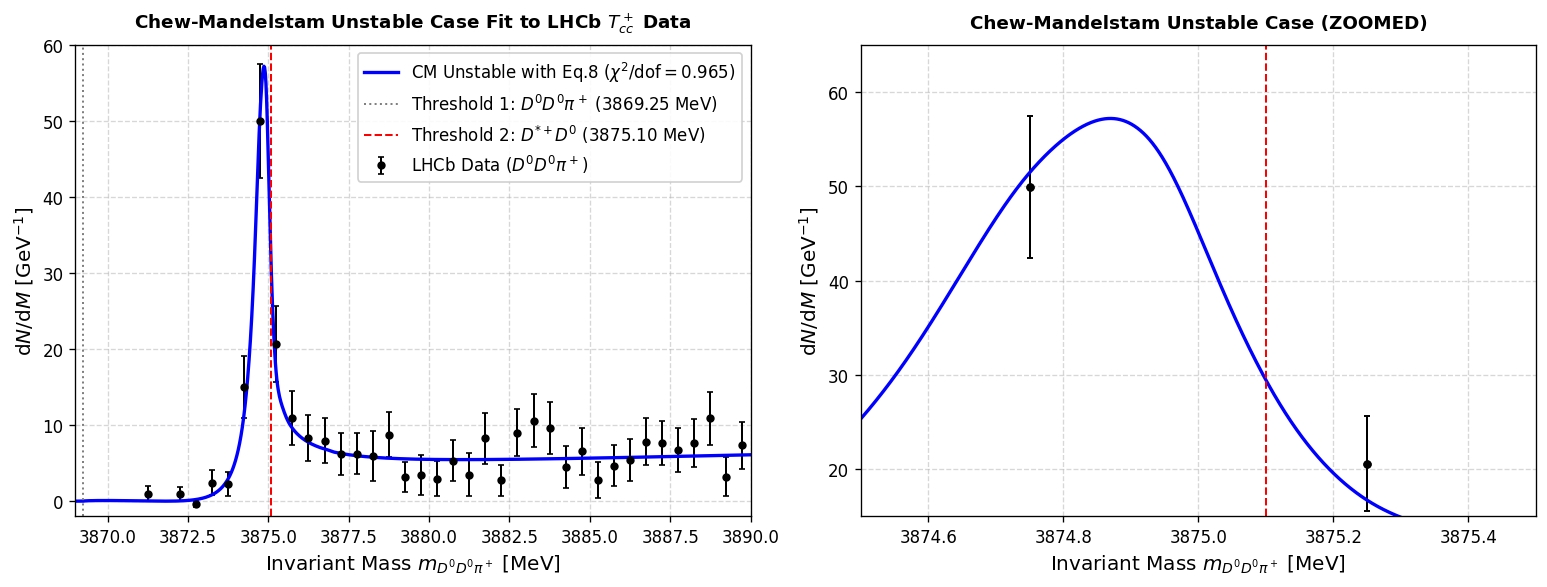

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.interpolate import CubicSpline
from scipy.optimize import least_squares
from iminuit import Minuit
from iminuit.cost import LeastSquares

# Physical Constants & Kinematics
m_D0 = 1.86484     
m_Dstar = 2.01026  
m_pion = 0.13957   
Gamma_Dstar = 83.4e-6  # GeV (83.4 keV width for D*+)

M1, m1 = m_D0 + m_pion, m_D0  # Channel 1: (D0 pi+) + D0 (3.86925 GeV)
M2_st, m2 = m_Dstar, m_D0     # Channel 2: D*+ + D0       (3.87510 GeV)
M2_unst = m_Dstar - 1j * (Gamma_Dstar / 2.0)

p_unit = m_pion

# Kinematics & Chew-Mandelstam Loop Function
def sqrt_rhc(z):
    """Complex square root with Right-Hand Cut along [0, +inf)."""
    z_c = np.asarray(z, dtype=np.complex128)
    r = np.abs(z_c)
    theta = np.angle(z_c)
    theta = np.where(theta < 0, theta + 2.0 * np.pi, theta)
    res = np.sqrt(r) * np.exp(1j * theta / 2.0)
    return res if isinstance(z, np.ndarray) else res.item()

def k_cm(s, M, m, sheet_sign=+1):
    """Center-of-mass momentum k(s) using Right-Hand Cut square root."""
    s_c = np.asarray(s, dtype=np.complex128) + 1e-12j
    W = np.sqrt(s_c)
    sth = (M + m)**2
    sdiff = (M - m)**2
    z_th = s_c - sth
    z_diff = s_c - sdiff
    return sheet_sign * (sqrt_rhc(z_th) * np.sqrt(z_diff)) / (2.0 * W)

def chew_mandelstam(s_val, M, m, sheet_sign=+1):
    """Chew-Mandelstam loop function with branch sign selection."""
    s_c = np.asarray(s_val, dtype=np.complex128) + 1e-12j
    sth = (M + m)**2
    sdiff = (M - m)**2
    lam = (s_c - sth) * (s_c - sdiff)
    rho = sheet_sign * np.sqrt(lam) / s_c
    
    term1 = ((M**2 - m**2)/(np.pi * s_c) - (M**2 + m**2)/(np.pi * (M**2 - m**2))) * np.log(m / M)
    term2 = 1.0 / np.pi
    num = np.sqrt(sth - s_c) - np.sqrt(sdiff - s_c)
    den = np.sqrt(sth - s_c) + np.sqrt(sdiff - s_c)
    
    ratio = num / (den + 1e-300j)
    ratio = np.where(ratio == 0, 1e-300 + 0j, ratio)
    
    term3 = (rho / np.pi) * np.log(ratio)
    return term1 + term2 + term3

def p1_func(s):
    sth = (M1 + m1) ** 2
    s_diff = (M1 - m1) ** 2
    lam = (s + 0j - sth) * (s + 0j - s_diff)
    return np.real(np.sqrt(lam)) / (2.0 * np.sqrt(s))

# Dai et al. Eq. (8) Convolution
g_Dstar = 0.4451      
Mtilde_Dstar = 2.01077     
sth_Dpi = (m_D0 + m_pion) ** 2  

def Sigma_Dpi(s_real):
    s_c = np.asarray(s_real, dtype=complex)
    C_val = chew_mandelstam(s_c, m_D0, m_pion, sheet_sign=+1)
    return (g_Dstar ** 2) * (s_c - sth_Dpi) * C_val

def f_Dpi_amplitude(s_real):
    D_val = Mtilde_Dstar ** 2 - s_real - Sigma_Dpi(s_real)
    return 1.0 / D_val

def Im_f_Dpi(sp):
    return np.imag(f_Dpi_amplitude(sp))

def _C2_conv_single(s_val, m2_mass, s_cutoff=9.0, sheet_sign=+1):
    peak_sp = Mtilde_Dstar ** 2
    def real_integrand(sp):
        C_val = chew_mandelstam(s_val, np.sqrt(sp), m2_mass, sheet_sign=sheet_sign)
        return np.real(C_val) * Im_f_Dpi(sp)
    def imag_integrand(sp):
        C_val = chew_mandelstam(s_val, np.sqrt(sp), m2_mass, sheet_sign=sheet_sign)
        return np.imag(C_val) * Im_f_Dpi(sp)

    re_int, _ = quad(real_integrand, sth_Dpi, s_cutoff, limit=400, points=[peak_sp], epsabs=1e-5, epsrel=1e-5)
    im_int, _ = quad(imag_integrand, sth_Dpi, s_cutoff, limit=400, points=[peak_sp], epsabs=1e-5, epsrel=1e-5)
    return (re_int + 1j * im_int) / np.pi

def build_C2_convoluted_interpolant(E_MeV_min=3850.0, E_MeV_max=3920.0, n_grid=400, s_cutoff=9.0):
    E_grid_MeV = np.linspace(E_MeV_min, E_MeV_max, n_grid)
    s_grid = (E_grid_MeV / 1000.0) ** 2

    C2_vals = np.array([_C2_conv_single(s_i + 1e-12j, m2, s_cutoff, sheet_sign=+1) for s_i in s_grid])

    spline_re = CubicSpline(s_grid, C2_vals.real)
    spline_im = CubicSpline(s_grid, C2_vals.imag)

    def C2_conv_interp(s_val):
        s_val = np.asarray(s_val)
        return spline_re(s_val.real) + 1j * spline_im(s_val.real)
    return C2_conv_interp

C2_conv_interp = build_C2_convoluted_interpolant()

# Model Yield
def cm_det_general(W_complex, K11, K12, K22, s1=+1, s2=+1):
    s = W_complex**2
    K_mat = np.array([[K11, K12], [K12, K22]], dtype=np.complex128)
    K_inv = np.linalg.inv(K_mat)
    C1 = chew_mandelstam(s, M1, m1, sheet_sign=s1)
    C2 = _C2_conv_single(s, m2, sheet_sign=s2)
    M_mat = K_inv - np.diag([C1, C2])
    return np.linalg.det(M_mat)

def model_yield(E_MeV, K11, K12, K22, alpha2, Na):
    E_GeV = E_MeV / 1000.0
    s = E_GeV**2
    K_mat = np.array([[K11, K12], [K12, K22]])
    try:
        K_inv = np.linalg.inv(K_mat)
    except np.linalg.LinAlgError:
        return np.ones_like(E_MeV) * 1e10

    yields = []
    for s_i in s:
        C1 = chew_mandelstam(s_i, M1, m1, sheet_sign=+1)
        C2 = C2_conv_interp(s_i)
        M_mat = np.array([[K_inv[0,0] - C1, K_inv[0,1]], [K_inv[1,0], K_inv[1,1] - C2]])
        det_M = M_mat[0,0] * M_mat[1,1] - M_mat[0,1] * M_mat[1,0]
        
        T11 = M_mat[1,1] / det_M
        T12 = -M_mat[0,1] / det_M
        F1 = T11 + alpha2 * T12
        p1 = p1_func(s_i)
        yields.append(Na * p1 * np.abs(F1)**2)
    return np.array(yields)

# Load Dataset
data_path = r"C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv"
df_data = pd.read_csv(data_path, comment='#')

data_mass_MeV = df_data.iloc[:, 0].values * 1000.0
data_yield = df_data.iloc[:, 3].values
data_err = df_data.iloc[:, 4].values

# Optimization (MINUIT)
init_params = dict(K11=-0.01204, K12=0.5080, K22=1.4447, alpha2=-0.3024, Na=1434.0)
cost = LeastSquares(data_mass_MeV, data_yield, data_err, model_yield)
m = Minuit(cost, **init_params)

m.limits["K11"] = (-10.0, 10.0)
m.limits["K12"] = (-10.0, 10.0)
m.limits["K22"] = (0.01, 20.0)
m.limits["alpha2"] = (-5.0, 5.0)
m.limits["Na"] = (0.1, 1e7)

m.errors["K11"] = 0.05
m.errors["K12"] = 0.03
m.errors["K22"] = 0.10
m.errors["alpha2"] = 0.01
m.errors["Na"] = 20.0

m.simplex()
m.migrad()
m.hesse()
    
p_opt = {k: m.values[k] for k in init_params.keys()}
p_err = {k: m.errors[k] for k in init_params.keys()}
chi2 = m.fval
dof = len(data_yield) - m.nfit
chi2_dof = chi2 / dof

# Unforced Pole Search & Riemann Sheet Identification
def find_and_identify_pole_unforced(K11, K12, K22):
    best_W = None
    best_s1, best_s2 = None, None
    min_res = float('inf')
    
    for s1_sign in [+1, -1]:
        for s2_sign in [+1, -1]:
            def denom_fn(W):
                return cm_det_general(W, K11, K12, K22, s1=s1_sign, s2=s2_sign)
            
            W = 3.8746 - 0.0003j
            h = 1e-7
            for _ in range(100):
                f = denom_fn(W)
                if abs(f) < 1e-12: break
                df = (denom_fn(W + h) - denom_fn(W - h)) / (2 * h)
                if abs(df) < 1e-15: break
                W -= f / df
                
            res = abs(denom_fn(W))
            if res < 1e-8 and W.imag <= 1e-4 and W.real > 3.86 and res < min_res:
                min_res = res
                best_W = W
                best_s1, best_s2 = s1_sign, s2_sign
                
    if best_W is None:
        return None
    M_R = best_W.real * 1000.0
    Gamma_R = -2.0 * best_W.imag * 1000.0
    
    s_pole = best_W**2
    k1_p = k_cm(s_pole, M1, m1, sheet_sign=best_s1) / p_unit
    k2_p = k_cm(s_pole, M2, m2, sheet_sign=best_s2) / p_unit
    
    s1_str = '+' if best_s1 == +1 else '-'
    s2_str = '+' if best_s2 == +1 else '-'
    
    # Corrected Sheet III mapping ([bb] instead of [tt])
    sheet_map = {
        ('+', '+'): "Sheet I [tt]",
        ('-', '+'): "Sheet II [bt]",
        ('-', '-'): "Sheet III [bb]",
        ('+', '-'): "Sheet IV [tb]"
    }
    
    return best_W, M_R, Gamma_R, k1_p, k2_p, s1_str, s2_str, sheet_map[(s1_str, s2_str)]

pole_res = find_and_identify_pole_unforced(p_opt["K11"], p_opt["K12"], p_opt["K22"])

# Summary Table
param_names = ["K11", "K12", "K22", "alpha2", "Na"]

print("=" * 90)
print(f"{'MINUIT Fit Parameter Table (Frazer-Hendry Unstable Case, Raw Yield)':^90}")
print("=" * 90)
print(f"{'Parameter':<12} | {'Fitted Value':>12} | {'Uncertainty':>12}")
print("-" * 90)
for name in param_names:
    val = p_opt[name]
    err = p_err[name]
    print(f"{name:<12} | {val:12.5f} | {err:12.5f}")
print("-" * 90)
print(f"Total Chi^2       : {chi2:.3f}")
print(f"Degrees of Freedom: {dof}")
print(f"Chi^2 / dof       : {chi2_dof:.3f}")
print("=" * 90)

if pole_res:
    W_p, M_R, Gamma_R, k1_p, k2_p, s1_tag, s2_tag, sheet_str = pole_res
    th1 = np.angle(k1_p)
    th2 = np.angle(k2_p)
    k1_v = (np.real(k1_p) * np.imag(k1_p) < 0)
    k2_v = (np.real(k2_p) * np.imag(k2_p) < 0)
    print(f"S-Matrix Pole: W_pole = {W_p.real:.6f} + i({W_p.imag:.6f}) GeV")
    print(f"Pole Mass   M_R   : {M_R:.3f} MeV")
    print(f"Pole Width  Gamma : {Gamma_R:.3f} MeV")
    print("-" * 90)
    print(f"Ch 1 Angle theta1 = {np.degrees(th1):.2f}° | k1 = {k1_p.real:.6f} + i({k1_p.imag:.6f}) | Re*Im<0: {k1_v}")
    print(f"Ch 2 Angle theta2 = {np.degrees(th2):.2f}° | k2 = {k2_p.real:.6f} + i({k2_p.imag:.6f}) | Re*Im<0: {k2_v}")
    print(f"Identified Riemann Sheet    : {sheet_str}")
print("=" * 90)

fig, ax = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
plt.errorbar(
    data_mass_MeV, data_yield, yerr=data_err,
    fmt='o', color='black', ecolor='black', elinewidth=1.2, capsize=2,
    markersize=4, label=r'LHCb Data ($D^0 D^0 \pi^+$)'
)
E_fine_MeV = np.linspace(3869.0, 3890.0, 1000)
yield_fit_fine = model_yield(
    E_fine_MeV,
    p_opt['K11'], p_opt['K12'], p_opt['K22'],
    p_opt['alpha2'], p_opt['Na']
)
m_th1 = (M1 + m1) * 1000.0
m_th2 = (m_Dstar + m2) * 1000.0

ax[0].errorbar(
    data_mass_MeV, data_yield, yerr=data_err,
    fmt='o', color='black', ecolor='black', elinewidth=1.2, capsize=2,
    markersize=4, label=r'LHCb Data ($D^0 D^0 \pi^+$)'
)
ax[0].plot(E_fine_MeV, yield_fit_fine, color='blue', lw=2, label=r'CM Unstable with Eq.8 ($\chi^2/\mathrm{dof} = ' + f'{chi2_dof:.3f}' + r'$)')
ax[0].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=r'Threshold 1: $D^0 D^0 \pi^+$ (' + f'{m_th1:.2f}' + r' MeV)')
ax[0].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=r'Threshold 2: $D^{*+} D^0$ (' + f'{m_th2:.2f}' + r' MeV)')
ax[0].set_title(r'Chew-Mandelstam Unstable Case Fit to LHCb $T_{cc}^+$ Data', fontsize=11, fontweight='bold', pad=10)
ax[0].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[0].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[0].set_xlim(3869, 3890)
ax[0].set_ylim(-2, 60)
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[0].legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)

E_fine_MeV_ZOOM = np.linspace(3874.0, 3876.0, 20000)
yield_fit_fine_zoom = model_yield(E_fine_MeV_ZOOM, p_opt['K11'], p_opt['K12'], p_opt['K22'], p_opt['alpha2'], p_opt['Na'])
ax[1].errorbar(
    data_mass_MeV, data_yield, yerr=data_err,
    fmt='o', color='black', ecolor='black', elinewidth=1.2, capsize=2,
    markersize=4, label=r'LHCb Data ($D^0 D^0 \pi^+$)'
)
ax[1].plot(E_fine_MeV_ZOOM, yield_fit_fine_zoom, color='blue', lw=2, label=r'CM Stable Raw ($\chi^2/\mathrm{dof} = ' + f'{chi2_dof:.3f}' + r'$)')
ax[1].axvline(m_th1, color='gray', linestyle=':', lw=1.2, label=r'Threshold 1: $D^0 D^0 \pi^+$ (' + f'{m_th1:.2f}' + r' MeV)')
ax[1].axvline(m_th2, color='red', linestyle='--', lw=1.2, label=r'Threshold 2: $D^{*+} D^0$ (' + f'{m_th2:.2f}' + r' MeV)')
ax[1].set_title(r'Chew-Mandelstam Unstable Case (ZOOMED)', fontsize=11, fontweight='bold', pad=10)
ax[1].set_xlabel(r'Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]', fontsize=12)
ax[1].set_ylabel(r'$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]', fontsize=12)
ax[1].set_xlim(3874.5, 3875.5)
ax[1].set_ylim(15, 65)
ax[1].grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()